## The Black Litterman Model



Import libraries

In [67]:
import yfinance as yf
import pandas as pd
import numpy as np
import datetime
import math
import matplotlib.pyplot as plt
import seaborn as sns

**S&P 500 SECTORS**

^SP500-15 Materials sector

^SP500-20 Industrial sector

^SP500-25 Consumer discretionary sector

^SP500-30 Consumer Staples sector

^SP500-35 Healthcare sector

^SP500-40 Financials sector

^SP500-45 Information Technology sector

^SP500-50 Telecommunication Services sector

^SP500-55 Utilities sector

^SP500-60 Real Estate sector

^GSPE Energy sector.

In [68]:
## Acquire data from Yahoo finance
sectors=["^SP500-15", "^SP500-20","^SP500-25","^SP500-30","^SP500-35","^SP500-40","^SP500-45","^SP500-50","^SP500-55", "^SP500-60","^GSPE" ]
start= datetime.datetime(2022,1,1)
end = datetime.datetime(2023,8,4)
data = yf.download(sectors, start=start, end=end)['Close']
data.head()

[*********************100%***********************]  11 of 11 completed


Ticker,^GSPE,^SP500-15,^SP500-20,^SP500-25,^SP500-30,^SP500-35,^SP500-40,^SP500-45,^SP500-50,^SP500-55,^SP500-60
Date,,,,,,,,,,,
2022-01-03,435.829987,561.820007,887.590027,1655.170044,804.549988,1627.819946,658.130005,3086.75000,268.970001,360.290009,321.630005
2022-01-04,450.899994,569.150024,905.630005,1644.069946,808.330017,1605.310059,675.260010,3051.47998,268.079987,359.119995,320.399994
2022-01-05,450.570007,568.690002,896.950012,1600.609985,808.070007,1593.930054,666.830017,2955.97998,260.200012,358.950012,310.089996
2022-01-06,460.890015,561.659973,901.010010,1595.359985,806.400024,1574.660034,677.140015,2941.72998,261.119995,355.170013,310.399994
2022-01-07,467.579987,561.169983,900.750000,1569.020020,807.650024,1567.500000,684.909973,2912.02002,260.299988,357.850006,308.700012


<Axes: title={'center': 'S&P 500 sectors'}, xlabel='Date', ylabel='level'>

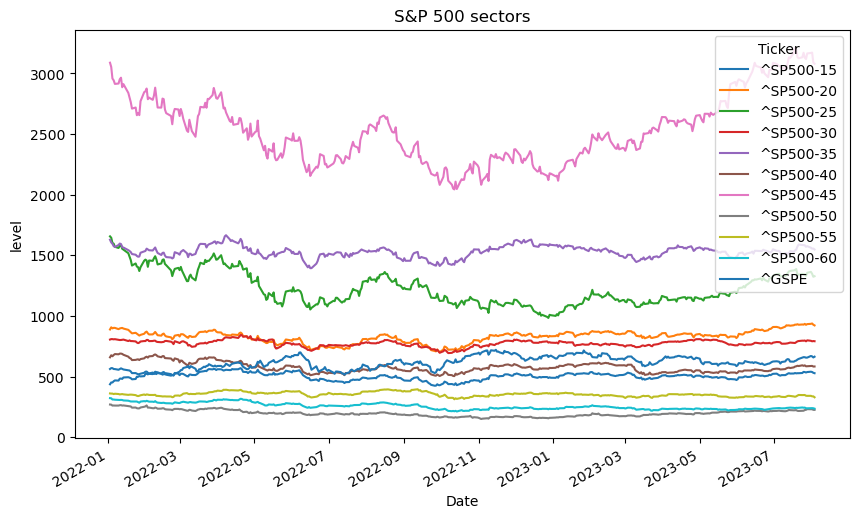

In [69]:
## plot data
data.plot.line(y=sectors, figsize=(10,6), title = 'S&P 500 sectors', ylabel='level')

<Axes: title={'center': 'Daily absolute returns'}, xlabel='Date', ylabel='level'>

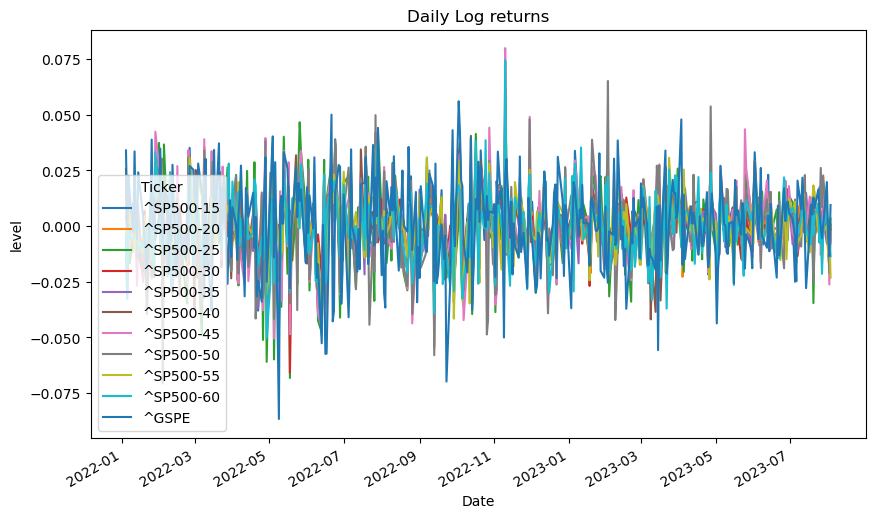

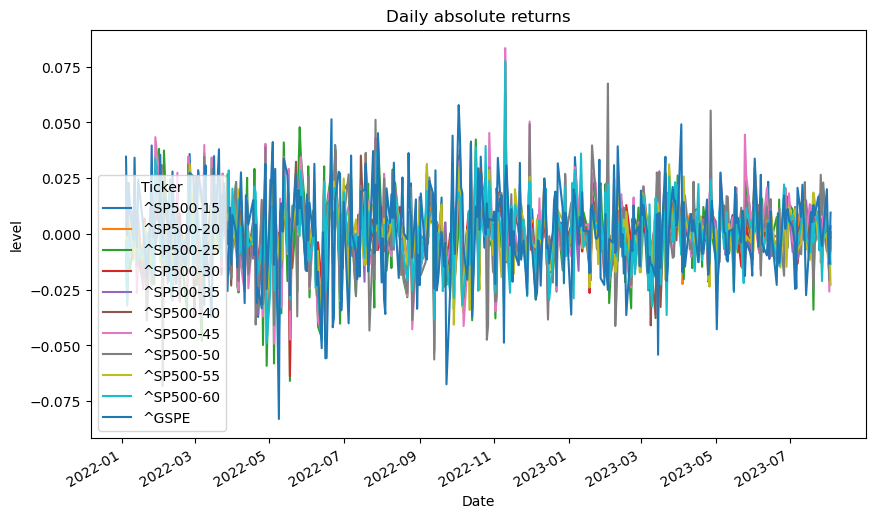

In [70]:
# geometric returns
df=np.log(data).diff()
df1= df.dropna()
df1*100
df2 = data.pct_change() ## daily absolute return
df2 = df2.dropna()
## plotting log returns
df1.plot.line(y=sectors, figsize=(10,6), title = 'Daily Log returns', ylabel='level')
df2.plot.line(y=sectors, figsize=(10,6), title = 'Daily absolute returns', ylabel='level')

In [71]:
## annualized mean returns and covariance matrix
def expected_returns(dataframe):
    expected_returns=[]
    for col in dataframe.columns:
        expected_returns.append(dataframe[col].mean()*252)
    return np.array(expected_returns)


In [72]:
returns = expected_returns(df1)
df_cov  = df1.cov()*252
df1_cor = df1.corr()

weights_sectors = np.array([0.02,0.08,0.11,0.075,0.135,0.13,0.275,0.09,0.02,0.02,0.045])
d = 0.62/0.21 ## 0.62 is the Sharpe ratio of S&P500 and 0.21 volatility of S&P 500 during the period
implied_equilibrium_returns= d*df_cov.dot(weights_sectors)
#implied_equilibrium_returns['Weights'] = weights_sectors
print(implied_equilibrium_returns)
df_results = pd.DataFrame({
    'Implied_Returns': implied_equilibrium_returns.values,
    'Weights': weights_sectors
}, index=implied_equilibrium_returns.index)

print(df_results)


Ticker
^GSPE        0.083621
^SP500-15    0.115297
^SP500-20    0.104208
^SP500-25    0.145116
^SP500-30    0.065654
^SP500-35    0.077168
^SP500-40    0.117391
^SP500-45    0.141691
^SP500-50    0.127713
^SP500-55    0.070361
^SP500-60    0.105951
dtype: float64
           Implied_Returns  Weights
Ticker                             
^GSPE             0.083621    0.020
^SP500-15         0.115297    0.080
^SP500-20         0.104208    0.110
^SP500-25         0.145116    0.075
^SP500-30         0.065654    0.135
^SP500-35         0.077168    0.130
^SP500-40         0.117391    0.275
^SP500-45         0.141691    0.090
^SP500-50         0.127713    0.020
^SP500-55         0.070361    0.020
^SP500-60         0.105951    0.045


# The Black Litterman model


After we have calculate dthe  the implied equilibium of returns, we calculate the new combined return vector given by the equation below:
$$
E[r] = \Big[ (\tau \Sigma)^{-1} + P^{T} \Omega^{-1} P \Big]^{-1} 
       \Big[ (\tau \Sigma)^{-1} \pi + P^{T} \Omega^{-1} q \Big]
$$
Refer the lesson notes for detailed description of the formula.

In [73]:
#df1.plot.line(y=sectors, figsize=(10,6), title = 'Daily Log returns', ylabel='level')
#df2.plot.line(y=sectors[9], figsize=(10,6), title = 'Daily absolute returns', ylabel='level')

In [74]:
## define the Q (View vector) which will be 3 x 1 matrix as K=3 (number of views)
Q = np.array([0.125,0.05,0.105])

## P is a  matrix whose rows contains the weight of each of the investor's individual views. So here P would be 3 x 11
P = [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.125],
    [0, 0, 0, 0, 0, 0, -0.5, 0.5, 0, 0, 0],
    [0.105, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]

In [75]:
p0 = np.array(P[0]).reshape(len(P[0]), 1)
view1_var = np.matmul(p0.T, np.matmul(df_cov.values, p0))
p1=np.array(P[1]).reshape(len(P[1]), 1)
view2_var = np.matmul(p1.T, np.matmul(df_cov.values, p1))
p2=np.array(P[2]).reshape(len(P[2]), 1)
view3_var = np.matmul(p2.T, np.matmul(df_cov.values, p2))
print(
    f'The Variance of View 1 Portfolio is {view1_var.item():.3f}, '
    f'and the standard deviation is {np.sqrt(view1_var).item():.3f}\n'
    f'The Variance of View 2 Portfolio is {view2_var.item():.3f}, '
    f'and the standard deviation is {np.sqrt(view2_var).item():.3f}\n'
    f'The Variance of View 3 Portfolio is {view3_var.item():.3f}, '
    f'and the standard deviation is {np.sqrt(view3_var).item():.3f}'
)

The Variance of View 1 Portfolio is 0.001, and the standard deviation is 0.030
The Variance of View 2 Portfolio is 0.010, and the standard deviation is 0.100
The Variance of View 3 Portfolio is 0.001, and the standard deviation is 0.034


As per lesson notes we are done till step 5, now step 6 would be to calculate $\Omega$, it is a K x k matrix that incorporates the manager's uncertainty about each view. 

$$
\Omega = \operatorname{diag}\!\big(P(\tau \Sigma)P^{T}\big)
$$
$$
$
\]


]




In [76]:
def error_cov_matrix(sigma, tau, P):
    P=np.array(P)
    matrix = np.diag(np.diag(P.dot(tau * df_cov).dot(P.T)))
    return matrix
tau = 0.025
omega = error_cov_matrix(df_cov, tau, P)*100
omega

array([[0.00218886, 0.        , 0.        ],
       [0.        , 0.02478098, 0.        ],
       [0.        , 0.        , 0.00282648]])

We move to the last step from lesson notes i.e., step 7, where we calculate the BL returns using the below formula

$E[r] = \big[(\tau \Sigma)^{-1} + P^{T}\Omega^{-1}P\big]^{-1}\big[(\tau \Sigma)^{-1}\pi + P^{T}\Omega^{-1}q\big]$
\]




In [77]:
sigma_scaled = df_cov * tau
P=np.array(P)
# adjustment = np.linalg.solve(P @ sigma_scaled @ P.T + omega,
#                              Q - P @ implied_equilibrium_returns)
# BL_return_vector = implied_equilibrium_returns + sigma_scaled @ P.T @ adjustment


BL_return_vector = (
    implied_equilibrium_returns
    + sigma_scaled.dot(P.T).dot(
        np.linalg.inv(P.dot(sigma_scaled).dot(P.T) + omega)
        .dot(Q - P.dot(implied_equilibrium_returns))
    )
)

BL_return_vector

Ticker
^GSPE        0.096265
^SP500-15    0.124902
^SP500-20    0.112614
^SP500-25    0.155532
^SP500-30    0.070618
^SP500-35    0.083125
^SP500-40    0.126017
^SP500-45    0.152097
^SP500-50    0.136770
^SP500-55    0.077547
^SP500-60    0.117040
dtype: float64

In [78]:
returns_table = pd.concat([implied_equilibrium_returns, BL_return_vector], axis=1) * 100
returns_table.columns = ['Implied Returns', 'BL Return Vector']
returns_table['Difference'] = returns_table['BL Return Vector'] - returns_table['Implied Returns']
returns_table.style.format('{:,.2f}%')

,Implied Returns,BL Return Vector,Difference
Ticker,,,
^GSPE,8.36%,9.63%,1.26%
^SP500-15,11.53%,12.49%,0.96%
^SP500-20,10.42%,11.26%,0.84%
^SP500-25,14.51%,15.55%,1.04%
^SP500-30,6.57%,7.06%,0.50%
^SP500-35,7.72%,8.31%,0.60%
^SP500-40,11.74%,12.60%,0.86%
^SP500-45,14.17%,15.21%,1.04%
^SP500-50,12.77%,13.68%,0.91%


In [79]:
# print("tau:", tau)
# print("sigma_scaled norm:", np.linalg.norm(sigma_scaled))
# print("omega diag:", np.diag(omega))
# print("Q:", Q)
# print("implied_equilibrium_returns:", implied_equilibrium_returns)


We would now calculate the BL weights

In [80]:
inverse_cov = pd.DataFrame(np.linalg.inv(df_cov.values), index=df_cov.columns, columns=df_cov.index)
BL_weights_vector = inverse_cov.dot(BL_return_vector)
BL_weights_vector = BL_weights_vector/sum(BL_weights_vector)
BL_weights_vector=pd.DataFrame(BL_weights_vector)
BL_weights_vector

,0
Ticker,
^GSPE,0.046020
^SP500-15,0.073854
^SP500-20,0.101549
^SP500-25,0.069238
^SP500-30,0.124628
^SP500-35,0.120012
^SP500-40,0.248043
^SP500-45,0.088915
^SP500-50,0.018463


In [81]:
df_results= pd.DataFrame(df_results)
Weights_table = pd.concat([df_results['Weights'], BL_weights_vector], axis=1) * 100
Weights_table.columns = ['Implied Weights', 'BL Weight Vector']
Weights_table['Difference'] = Weights_table['BL Weight Vector'] - Weights_table['Implied Weights']
Weights_table.style.format('{:,.2f}%')

,Implied Weights,BL Weight Vector,Difference
Ticker,,,
^GSPE,2.00%,4.60%,2.60%
^SP500-15,8.00%,7.39%,-0.61%
^SP500-20,11.00%,10.15%,-0.85%
^SP500-25,7.50%,6.92%,-0.58%
^SP500-30,13.50%,12.46%,-1.04%
^SP500-35,13.00%,12.00%,-1.00%
^SP500-40,27.50%,24.80%,-2.70%
^SP500-45,9.00%,8.89%,-0.11%
^SP500-50,2.00%,1.85%,-0.15%


In [82]:
# # Calculate BL weights optimised weights
# # MV_weights_vector = inverse_cov.dot(excess_asset_returns.mean())
# # MV_weights_vector = MV_weights_vector/sum(MV_weights_vector)
# weights_table = pd.concat([BL_weights_vector, asset_weights, MV_weights_vector], axis=1) * 100
# weights_table.columns = ['BL Weights', 'Market Cap Weights', 'Mean-Var Weights']
# weights_table['BL/Mkt Cap Diff'] = weights_table['BL Weights'] - weights_table['Market Cap Weights']
# weights_table.style.format('{:,.2f}%')